<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/04_Botnet_DGA_Detection/QHTC_BotnetDGA_Tehrani2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QHTC for DGA-botnet detection: Tehrani et al. (2024) step by step

This notebook re-implements, runs and checks the experiments of

> Madjid G. Tehrani, Eldar Sultanow, William J. Buchanan, Malik Amir, Anja Jeschke, Mahkame Houmani, Raymond Chow and
> Mouad Lemoudden, "Stabilized quantum-enhanced SIEM architecture and speed-up through Hoeffding tree algorithms enable
> quantum cybersecurity analytics in botnet detection", *Scientific Reports* 14, 1732 (2024).
> https://doi.org/10.1038/s41598-024-51941-8

The paper publishes its code (seven Colab notebooks, one per experiment) at
https://github.com/Sultanow/quantum-botnet-detection and hosts the two sample files it uses on public Azure blobs, so
everything below follows the published code line by line where the paper itself is silent.

**What the notebook does.** It downloads the paper's two samples of the IEEE *Botnet DGA Dataset* (1000 and 5000
domain names, seven engineered features each), rebuilds the paper's new classifier, the *quantum-enhanced Hoeffding
tree classifier* (QHTC), in two steps exactly as the paper describes them: (1) every feature row is written into a
7-qubit `ZFeatureMap` state and the "quantum walk", the summed trace distance between neighbouring qubits around the
cycle, is measured with Qiskit; (2) a Hoeffding tree is trained batch-wise on that number. It reproduces the paper's
Table 6 (accuracy, F1 and AUC per batch) with the paper's own tree code and batch protocol, explains why those numbers
come out as they do, and then re-runs the same experiment without test-set leakage with a textbook Hoeffding tree
(`river`). It also trains the paper's five other hybrid quantum binary classifiers (QSVC, PegasosQSVC, VQC,
SamplerQNN, EstimatorQNN; Table 5, Aer rows) on the 1000-sample file with the paper's feature map, ansatz and optimiser,
puts classical baselines next to every quantum model on identical inputs, and ends with a claim-by-claim comparison.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell
installs pinned Qiskit versions and `river`; if Colab asks to restart the session, restart and run all again. Nothing in
the notebook needs a GPU, an IBM Quantum account or Azure Quantum credits: the paper's real-device rows (Table 4) and
cloud-emulator rows cannot be rerun here and are marked as such.

**Runtime.** `FAST_MODE = True` (3 batches of 1000 for QHTC, 300 domain names for the five other classifiers, 25
optimiser iterations) takes about 5 minutes on a laptop CPU. `FAST_MODE = False` (all 5001 rows, 700/300 split as in
the paper's code, 100 COBYLA iterations) took 30 minutes on the same machine; the committed outputs are from that run.

**What you get at the end.** A table with every number of the paper's Tables 5 and 6 (Aer/simulator rows) next to the
value this notebook obtains, a verdict per claim, a leakage-free version of the headline result, and a critical
reading of the paper with exercises.

## The paper in one page

**Problem.** Botnets locate their command-and-control servers through *domain generation algorithms* (DGA): the malware
computes thousands of pseudo-random domain names per day and the operator registers one of them. A SIEM that can tell a
DGA name (`xkqzvhtr.net`) from a legitimate one (`wikipedia.org`) from DNS telemetry can block the whole botnet. The paper
treats this as binary classification of seven numbers computed from each domain name.

**Decision.** For every domain name, benign (class 0) or DGA (class 1).

**Data.** The IEEE *Botnet DGA Dataset* (Suryotrisongko, 2020; DOI 10.21227/rg6z-z622): 1,803,333 names from the Alexa
top-1M list and ten DGA families, with seven engineered features: `CharLength`, `Entropy` (Shannon entropy of the
characters), `REAlexa` (Kullback-Leibler divergence to the Alexa character distribution), `MinREBotnets` (minimum KL
divergence to the ten DGA families), `InformationRadius` (Jensen-Shannon divergence to the families), `TreeNewFeature`
(the output of a decision tree trained on four of the other features) and `nGramReputation_Alexa` (an n-gram reputation
score). The paper draws fixed random samples: 1000 rows for the five known classifiers (as in its reference [12]), 5000
rows for QHTC, 100 rows for real devices. Both sample files are published with the code and are used here unchanged.

**Method.** Five known hybrid quantum binary classifiers (HQBC) from `qiskit-machine-learning` 0.5 with a 7-qubit
`ZFeatureMap`, the `RealAmplitudes` ansatz and COBYLA (or Pegasos' SGD) are run on the Aer simulator, on three
real-device emulators (IonQ, Rigetti, Quantinuum via Azure Quantum) and on the three real devices. The new model, QHTC,
maps each feature row to a 7-qubit `ZFeatureMap` state, computes the reduced density matrix of every qubit and sums the
trace distances between neighbouring qubits around the cycle 0-1-2-...-6-0 ("quantum walk"), then feeds that number to
an incremental Hoeffding tree (Algorithms 1-3) trained batch-wise on five batches of 1000 rows.

**Claims checked here** (Tables 5 and 6; everything on the Aer simulator or the Rigetti emulator):

| Claim | Paper |
|---|---|
| QHTC, 5000 samples: accuracy / F1 / AUC per batch | 57.1/4.5/51.1, 99.0/98.8/98.9, 100/100/100, 100/100/100, 100/100/100 |
| QHTC average accuracy / F1 / AUC | 91.2 % / 80.7 % / 90.0 % ; "100 % already after three of five batches" |
| QHTC total execution time (Rigetti emulator) | 1687 s, "two orders of magnitude" below the other HQBCs |
| VQC-Aer (COBYLA), 1000 samples | 54 % (ref. [12] reports 76.8 % with the same setting) |
| PegasosQSVC-Aer, 1000 samples | 90 %, 45 s |
| QSVC-Aer, 1000 samples | 87 %, 3091 s |
| SamplerQNN-Aer, 1000 samples | 76 %, 374 s |
| EstimatorQNN-Aer, 1000 samples | 84 %, 410 s |
| Real devices (Table 4), 100 samples | 39-59 % ; cannot be rerun without Azure Quantum access |

### What follows the paper and what had to be chosen

| Item | Paper (text or published code) | This notebook |
|---|---|---|
| Data files | `BotnetDgaDataset_1000.csv`, `BotnetDgaDataset_5000_newMethod.csv` from the authors' Azure blobs | same URLs, cached in `DATA_DIR`; if the 1000-row blob is gone, the first 1000 rows of the 5000-row file are used (`# CHOICE`) |
| Positive class | header of the 1000-row file: `benign, dga` = 0, 1 | DGA = 1 is the positive class in every metric |
| QHTC feature scaling | `StandardScaler` fitted on all 5000 rows (code) | paper-protocol run: same; leakage-free run: fitted on the training batches of each fold (`# CHOICE`) |
| Quantum walk | `ZFeatureMap(1)` per feature, `statevector_simulator`, `partial_trace`, trace distance by singular values, cycle 0-1-...-6-0 | identical with Qiskit 2.x `Statevector`/`partial_trace`; checked against the closed form; closed form used for rows beyond `N_WALK_QISKIT` |
| Hoeffding tree (paper protocol) | the authors' own `HoeffdingTreeClassifier` (Algorithms 1-2), delta 0.01, tie threshold 0.05, batch loop of Algorithm 3 | the same class, copied from `Paper02_QHTC_AER_Simulator.ipynb` |
| Hoeffding tree (leakage-free) | not in the paper | `river.tree.HoeffdingTreeClassifier` with the paper's delta and tau, grace period 50, fresh tree per fold / prequential stream (`# CHOICE`) |
| Batches | five batches of 1000 (the code's loop also runs a sixth "batch" with the one leftover row) | five batches; the leftover row is reported but excluded from the averages |
| Split for the 1000-sample HQBCs | `train_size=700, shuffle=False` (QSVC, Pegasos); `random_state=7` (VQC) | first 700 / last 300 rows for every model (`# CHOICE`), plus repeated shuffled splits for the cheap models |
| Feature scaling for HQBCs | QSVC/Pegasos: `MinMaxScaler((0, pi))` fitted on all rows; VQC: no scaling; QNNs: see below | `MinMaxScaler((0, pi))` fitted on the training rows only (`# CHOICE`); the VQC is also run on unscaled features as in the code |
| Feature map / ansatz | `ZFeatureMap(7, reps=1)`; VQC: `RealAmplitudes(7, reps=1, entanglement="pairwise")`; QNN code: `ZZFeatureMap(7)` + `RealAmplitudes` (reps 1 / 3) | identical (`z_feature_map`, `zz_feature_map`, `real_amplitudes`); the QNN feature map follows the code, not the text (`QNN_FEATURE_MAP`) |
| Optimiser | text: COBYLA for VQC/QSVC/QNNs; code: `COBYLA()` for the VQC, `SPSA()` for the QNNs; Pegasos: C = 1000, 100 steps | COBYLA with `MAXITER` iterations for VQC and QNNs (`# CHOICE`); Pegasos C = 1000, 100 steps |
| Simulator | Aer `qasm_simulator`, 1024 shots (VQC, Pegasos, QNNs); `statevector_simulator` (QSVC, walk) | Aer `SamplerV2`/`EstimatorV2` with 1024 shots and a seed; `FidelityStatevectorKernel` for QSVC/Pegasos |
| QNN training data | code: the botnet CSV is loaded and then **overwritten by 50 random synthetic points**, scored on the training set | QNNs trained on the botnet split; the code's synthetic path is rerun separately to show where the 76 % / 84 % come from |
| Seeds | `algorithm_globals.random_seed = 12345` (kernels), 42 (QNN), none elsewhere | `SEED = 42` everywhere |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning / river is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("river") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "river==0.26.1" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning and river already present; skipping pip install.")

qiskit-machine-learning and river already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 5 minutes. False: the paper's sizes (about 30 min on a 2-core CPU).
SEED      = 42              # CHOICE: the paper seeds only its kernels (12345) and QNNs (42)

N_FEATURES = 7              # the seven engineered features of the IEEE Botnet DGA Dataset
N_QUBITS   = 7              # one qubit per feature (ZFeatureMap)
BATCH_SIZE = 1000           # paper: five batches of 1000 rows for QHTC

if FAST_MODE:
    N_QHTC_ROWS    = 3000   # three batches instead of five
    N_WALK_QISKIT  = 200    # rows whose quantum walk is simulated with Qiskit (closed form for the rest)
    N_HQBC         = 300    # rows of the 1000-sample file used for the five other classifiers
    TRAIN_SIZE     = 210    # 70 % / 30 % as in the paper's 700 / 300
    MAXITER        = 25     # COBYLA iterations for VQC and QNNs
    N_SEEDS        = 2      # repeated shuffled splits for the cheap models (mean +- std)
else:
    N_QHTC_ROWS    = None   # all 5001 rows of the file (five batches + one leftover row)
    N_WALK_QISKIT  = None   # every row through Qiskit
    N_HQBC         = 1000   # the whole 1000-sample file
    TRAIN_SIZE     = 700    # paper: train_size=700, test 300
    MAXITER        = 100    # CHOICE: the paper's COBYLA() ran with its default budget (about 190 evaluations for the VQC)
    N_SEEDS        = 3

SHOTS          = 1024       # paper's code: shots=1024 on Aer qasm_simulator
PEGASOS_C      = 1000       # paper's code: C = 1000
PEGASOS_STEPS  = 100        # paper's code: tau = 100
QNN_FEATURE_MAP = "zz"      # "zz" as in the published QNN notebooks, "z" as the paper's text says
VQC_REPS, VQC_ENTANGLEMENT = 1, "pairwise"   # paper's code: RealAmplitudes(7, reps=1, entanglement="pairwise")

HT_DELTA, HT_TAU = 0.01, 0.05   # paper's Hoeffding tree: delta=0.01, tie_threshold=0.05
HT_GRACE_PERIOD  = 50           # CHOICE: river's grace period (the paper's code attempts a split after every row)

DATA_DIR  = "data"
URL_5000  = "https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"              # Paper02_QHTC_AER_Simulator.ipynb
URL_1000  = "https://aq5efd7d2644dd406cb3ec2d.blob.core.windows.net/dga/BotnetDgaDataset_1000.csv"       # Paper03..07 notebooks
IBM_TOKEN = ""              # not used: nothing in this notebook runs on hardware

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import clear_output, display
from scipy.stats import skew, kurtosis

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit.library import z_feature_map, zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace
from qiskit_aer.primitives import SamplerV2 as AerSampler, EstimatorV2 as AerEstimator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC, PegasosQSVC, VQC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA, SPSA
from qiskit_machine_learning.utils import algorithm_globals

import river
from river import tree as river_tree

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("river", river.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| QHTC rows:", N_QHTC_ROWS or "all", "| HQBC rows:", N_HQBC, "| MAXITER =", MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
river 0.26.1 | numpy 2.5.4 | pandas 3.0.6
scikit-learn 1.9.1
FAST_MODE = False | QHTC rows: all | HQBC rows: 1000 | MAXITER = 100


## 1. The IEEE Botnet DGA dataset and the paper's two sample files

The full dataset (1.8 million names, 205 MB) sits behind an IEEE DataPort login, but the paper's notebooks download the
two fixed random samples the experiments use from public Azure storage containers: `BotnetDgaDataset_1000.csv` (1000
rows, used by VQC, QSVC, PegasosQSVC, SamplerQNN and EstimatorQNN) and `BotnetDgaDataset_5000_newMethod.csv` (5001 rows,
used by QHTC). Both are fetched below and cached in `DATA_DIR`. The 1000-row file carries a scikit-learn style header
line (`1000,7,benign,dga`), which tells us that class 0 is *benign* and class 1 is *DGA*; the 5000-row file has a normal
header. Column names follow the IEEE DataPort listing; the paper's Table 2 calls `Entropy` "EntropyValue", `REAlexa`
"RelativeEntropy" and `nGramReputation_Alexa` "Reputation".

If a blob disappears, the loader falls back to the first 1000 rows of the other file, or to a copy you place in
`DATA_DIR` yourself (the full dataset: https://ieee-dataport.org/open-access/botnet-dga-dataset).

In [4]:
COLS     = ["Entropy", "REAlexa", "MinREBotnets", "InformationRadius", "CharLength", "TreeNewFeature", "nGramReputation_Alexa", "Result"]
FEATURES = COLS[:-1]
CLASS_NAMES = ["benign (0)", "dga (1)"]

def fetch(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=120); r.raise_for_status()
        open(path, "wb").write(r.content)
        print("downloaded", os.path.basename(path), f"({len(r.content)/1e3:.0f} kB)")
    else:
        print("using cached", path)
    return path

def load_5000():
    path = os.path.join(DATA_DIR, "BotnetDgaDataset_5000_newMethod.csv")
    try:
        fetch(URL_5000, path)
    except Exception as e:
        raise RuntimeError(f"could not download the 5000-row file ({type(e).__name__}); place it in {DATA_DIR}/ (see the IEEE DataPort link above)")
    df = pd.read_csv(path, encoding="utf-8-sig")          # the file starts with a byte-order mark
    df.columns = COLS
    return df

def load_1000(df5000):
    path = os.path.join(DATA_DIR, "BotnetDgaDataset_1000.csv")
    try:
        fetch(URL_1000, path)
        return pd.read_csv(path, header=None, skiprows=1, names=COLS)   # first line is "1000,7,benign,dga,,,,"
    except Exception as e:
        print(f"1000-row blob unavailable ({type(e).__name__}); # CHOICE: using the first 1000 rows of the 5000-row file instead")
        return df5000.iloc[:1000].reset_index(drop=True)

t0 = time.time()
df5000 = load_5000()
df1000 = load_1000(df5000)
print(f"loaded in {time.time()-t0:.1f} s: 5000-file {df5000.shape}, 1000-file {df1000.shape}")
for name, d in [("5000-file", df5000), ("1000-file", df1000)]:
    vc = d["Result"].value_counts().sort_index()
    print(f"{name}: benign {vc.get(0, 0)}, dga {vc.get(1, 0)} ({100*d['Result'].mean():.1f} % DGA), "
          f"missing values {int(d.isnull().sum().sum())}, duplicate rows {int(d.duplicated().sum())}")
overlap = len(df1000.merge(df5000.drop_duplicates(), how="inner"))
print(f"rows shared by the two files: {overlap} (they are different random samples of the 1.8 M names)")
df5000.head()

using cached data\BotnetDgaDataset_5000_newMethod.csv
using cached data\BotnetDgaDataset_1000.csv
loaded in 0.0 s: 5000-file (5001, 8), 1000-file (1000, 8)
5000-file: benign 2763, dga 2238 (44.8 % DGA), missing values 0, duplicate rows 31
1000-file: benign 551, dga 449 (44.9 % DGA), missing values 0, duplicate rows 1
rows shared by the two files: 15 (they are different random samples of the 1.8 M names)


,Entropy,REAlexa,MinREBotnets,InformationRadius,CharLength,TreeNewFeature,nGramReputation_Alexa,Result
0,3.013071,1.055617,0.889698,0.628782,21,0.107095,152.009430,0
1,3.546594,0.786072,0.805445,0.520243,17,0.367645,133.570536,0
2,3.202820,1.302522,0.479128,0.590865,20,0.967923,61.759207,1
3,3.121654,0.934857,0.656545,0.599781,28,0.487624,184.481562,1
4,3.558519,0.702511,0.586947,0.499722,25,0.667705,138.302631,0


,mean (paper),mean (5000-file),std (paper),std (5000-file),median (paper),median (5000-file),max (paper),max (5000-file),skew (paper),skew (5000-file),kurt (paper),kurt (5000-file)
feature,,,,,,,,,,,,
CharLength,17.20,17.16,6.82,6.78,16.00,16.00,73.00,41.00,0.81,0.82,0.02,-0.20
Entropy,3.02,3.02,0.53,0.52,3.04,3.03,4.78,4.44,-0.40,-0.37,0.83,0.89
REAlexa,1.66,1.67,0.82,0.85,1.55,1.56,10.10,10.01,1.63,2.00,6.91,9.91
MinREBotnets,1.28,1.29,0.57,0.57,1.23,1.23,5.99,5.08,0.84,0.88,1.24,1.52
InformationRadius,0.65,0.65,0.11,0.11,0.65,0.65,1.17,1.12,0.34,0.40,0.12,0.32
TreeNewFeature,0.45,0.44,0.34,0.33,0.35,0.35,0.99,0.99,0.38,0.39,-1.52,-1.52
nGramReputation_Alexa,81.66,81.34,54.12,54.07,64.51,64.66,436.31,314.29,0.99,1.02,0.21,0.35


Means and medians of the 5001-row sample agree with the paper's Table 2 to the second decimal; the maxima are smaller because
a 5000-row sample rarely contains the extreme names of 1.8 M (e.g. a 73-character domain).


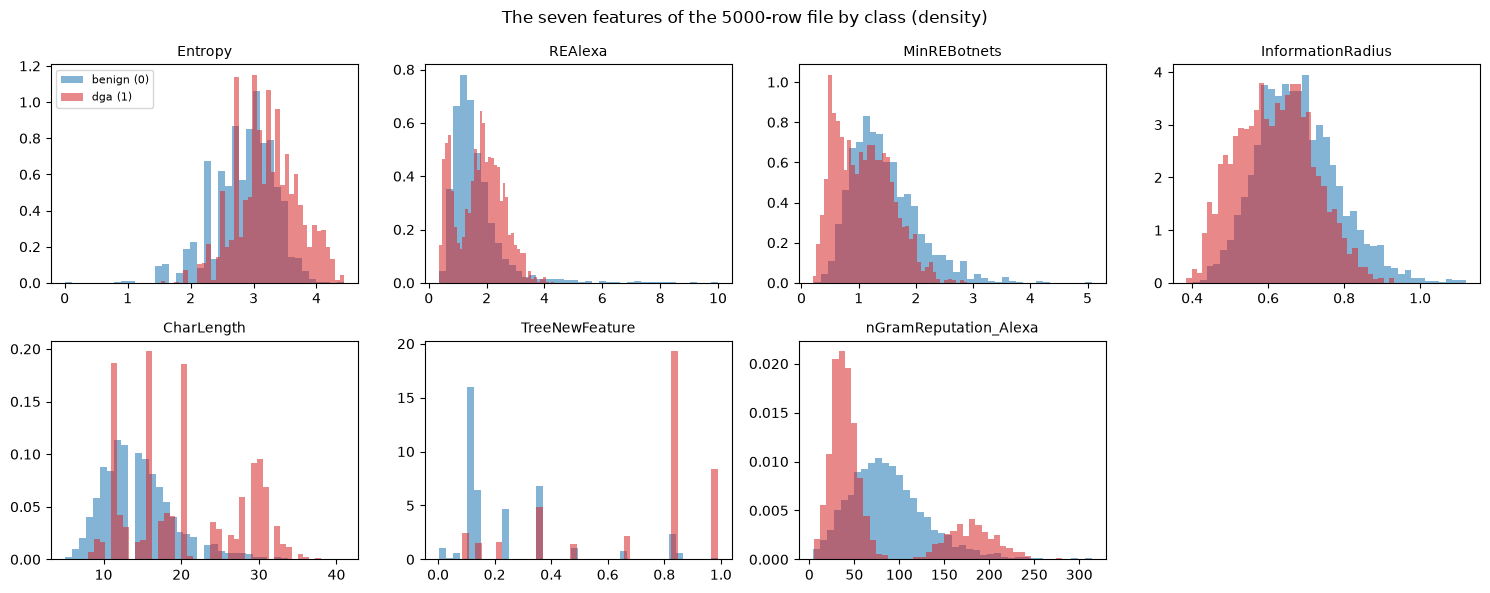

In [5]:
# The paper's Table 2 (descriptive statistics of the seven features over the whole 1.8 M-row dataset) next to the 5001-row sample.
PAPER_TABLE2 = {   # feature: (mean, std, min, median, max, skewness, kurtosis)
    "CharLength":            (17.20, 6.82, 4.00, 16.00, 73.00, 0.81, 0.02),
    "Entropy":               (3.02, 0.53, 0.00, 3.04, 4.78, -0.40, 0.83),
    "REAlexa":               (1.66, 0.82, 0.20, 1.55, 10.10, 1.63, 6.91),
    "MinREBotnets":          (1.28, 0.57, 0.00, 1.23, 5.99, 0.84, 1.24),
    "InformationRadius":     (0.65, 0.11, 0.24, 0.65, 1.17, 0.34, 0.12),
    "TreeNewFeature":        (0.45, 0.34, 0.00, 0.35, 0.99, 0.38, -1.52),
    "nGramReputation_Alexa": (81.66, 54.12, 0.00, 64.51, 436.31, 0.99, 0.21),
}
rows = []
for f, (m, s, lo, med, hi, sk, ku) in PAPER_TABLE2.items():
    v = df5000[f].values.astype(float)
    rows.append({"feature": f, "mean (paper)": m, "mean (5000-file)": round(v.mean(), 2), "std (paper)": s, "std (5000-file)": round(v.std(ddof=1), 2),
                 "median (paper)": med, "median (5000-file)": round(float(np.median(v)), 2), "max (paper)": hi, "max (5000-file)": round(v.max(), 2),
                 "skew (paper)": sk, "skew (5000-file)": round(float(skew(v)), 2), "kurt (paper)": ku, "kurt (5000-file)": round(float(kurtosis(v)), 2)})
table2 = pd.DataFrame(rows).set_index("feature")
display(table2)
print("Means and medians of the 5001-row sample agree with the paper's Table 2 to the second decimal; the maxima are smaller because")
print("a 5000-row sample rarely contains the extreme names of 1.8 M (e.g. a 73-character domain).")

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), FEATURES):
    for c, col in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(df5000.loc[df5000.Result == c, f], bins=40, alpha=0.55, color=col, label=CLASS_NAMES[c], density=True)
    ax.set_title(f, fontsize=10)
axes[0, 0].legend(fontsize=8); axes[1, 3].axis("off")
fig.suptitle("The seven features of the 5000-row file by class (density)"); plt.tight_layout(); plt.show()

## 2. QHTC step 1: the "quantum walk" feature

The paper maps every feature row $x = (x_0, \dots, x_6)$ (after standardisation) into a 7-qubit `ZFeatureMap` state.
`ZFeatureMap` with one repetition applies a Hadamard and then a phase gate $P(2x_i)$ to qubit $i$, so the state is a
*product* state

$$|\phi(x)\rangle = \bigotimes_{i=0}^{6} \frac{|0\rangle + e^{2 i x_i}|1\rangle}{\sqrt 2}.$$

The code then takes the reduced density matrix $\rho_i$ of each qubit (a partial trace over the other six), computes
the trace distance $D(\rho_i, \rho_{i+1}) = \tfrac12 \|\rho_i - \rho_{i+1}\|_1$ between neighbours around the cycle
$0 \to 1 \to \dots \to 6 \to 0$, and sums the seven distances. The paper calls this sum the *quantum walk* and it is
the single number the Hoeffding tree sees.

Because the state is a product state, every $\rho_i$ is pure and the trace distance between two pure qubit states is
$\sqrt{1 - |\langle\phi_i|\phi_{i+1}\rangle|^2}$ with $|\langle\phi_i|\phi_{i+1}\rangle| = |\cos(x_i - x_{i+1})|$, so

$$\text{walk}(x) = \sum_{i=0}^{6} \big|\sin(x_i - x_{i+1 \bmod 7})\big| .$$

The cell below implements the measurement with Qiskit exactly as the paper's `QHTC_Distance_AER` does (statevector,
`partial_trace`, trace distance), checks it on the paper's own example (`parameters = [1, 2, ..., 7]` gives
`5.3282414070463044` in the published notebook) and against the closed form on `N_WALK_QISKIT` real rows. The closed
form is then used for the remaining rows: it is the same number, computed in nanoseconds instead of milliseconds.

paper's example parameters 1..7: Qiskit 5.3282414070462991 | closed form 5.3282414070463053 | published notebook 5.3282414070463044


Qiskit statevector walk for 5001 rows: 9.6 s (1.9 ms/row); max |Qiskit - closed form| = 9.8e-15
quantum walk of 5001 rows: min 1.099, max 6.520, distinct values 4970


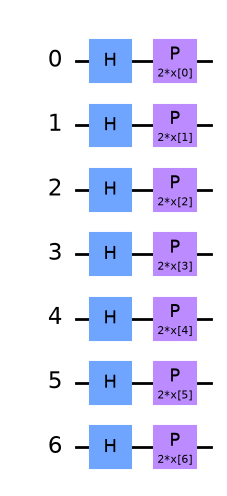

In [6]:
def trace_distance(rho, sigma):
    ev = np.linalg.eigvalsh((rho - sigma).data)          # the difference is Hermitian: 1/2 sum |eigenvalues| = 1/2 trace norm
    return 0.5 * float(np.abs(ev).sum())

def quantum_walk_qiskit(x):
    """The paper's QHTC distance: ZFeatureMap state of the 7 features, reduced density matrix per qubit,
    trace distance between cyclic neighbours, summed."""
    qc = z_feature_map(N_QUBITS, reps=1).assign_parameters(np.asarray(x, dtype=float))   # H + P(2 x_i) on qubit i
    sv = Statevector(qc)
    dms = [DensityMatrix(partial_trace(sv, [j for j in range(N_QUBITS) if j != i])) for i in range(N_QUBITS)]
    return sum(trace_distance(dms[i], dms[(i + 1) % N_QUBITS]) for i in range(N_QUBITS))

def quantum_walk_closed_form(X):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    return np.abs(np.sin(X - np.roll(X, -1, axis=1))).sum(axis=1)

example = np.arange(1, 8, dtype=float)
print(f"paper's example parameters 1..7: Qiskit {quantum_walk_qiskit(example):.16f} | closed form {quantum_walk_closed_form(example)[0]:.16f}"
      f" | published notebook 5.3282414070463044")

# the paper standardises all 5000 rows at once (StandardScaler.fit_transform on the whole file)
df_q  = df5000 if N_QHTC_ROWS is None else df5000.iloc[:N_QHTC_ROWS]
X_q_raw = df_q[FEATURES].values.astype(float)
y_q     = df_q["Result"].values.astype(int)
X_q_std = StandardScaler().fit_transform(X_q_raw)        # paper protocol (leakage-free refit comes in section 4)

n_check = len(X_q_std) if N_WALK_QISKIT is None else min(N_WALK_QISKIT, len(X_q_std))
t0 = time.perf_counter()
walk_qiskit = np.array([quantum_walk_qiskit(x) for x in X_q_std[:n_check]])
t_qiskit = time.perf_counter() - t0
walk_closed = quantum_walk_closed_form(X_q_std)
assert np.allclose(walk_qiskit, walk_closed[:n_check], atol=1e-9), "Qiskit simulation and closed form disagree"
print(f"Qiskit statevector walk for {n_check} rows: {t_qiskit:.1f} s ({1e3*t_qiskit/n_check:.1f} ms/row); max |Qiskit - closed form| = "
      f"{np.abs(walk_qiskit - walk_closed[:n_check]).max():.1e}")
walk_q = walk_closed.copy(); walk_q[:n_check] = walk_qiskit            # Qiskit values where simulated, closed form elsewhere
print(f"quantum walk of {len(walk_q)} rows: min {walk_q.min():.3f}, max {walk_q.max():.3f}, distinct values {len(np.unique(walk_q))}")

z_feature_map(N_QUBITS, reps=1).draw("mpl", fold=-1, style="clifford")

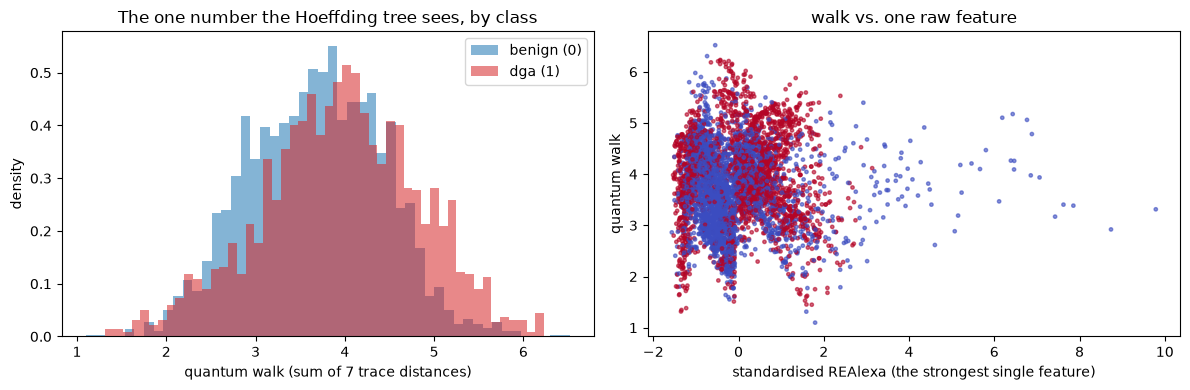

ranking power (AUC) of the walk alone: 0.595 | best single raw feature: TreeNewFeature 0.874


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c, col in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0].hist(walk_q[y_q == c], bins=50, alpha=0.55, color=col, label=CLASS_NAMES[c], density=True)
axes[0].set_xlabel("quantum walk (sum of 7 trace distances)"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("The one number the Hoeffding tree sees, by class")
axes[1].scatter(X_q_std[:, 1], walk_q, c=y_q, cmap="coolwarm", s=6, alpha=0.6)
axes[1].set_xlabel("standardised REAlexa (the strongest single feature)"); axes[1].set_ylabel("quantum walk")
axes[1].set_title("walk vs. one raw feature")
plt.tight_layout(); plt.show()

auc_walk = roc_auc_score(y_q, walk_q); auc_walk = max(auc_walk, 1 - auc_walk)
best_single = max((max(roc_auc_score(y_q, X_q_std[:, j]), 1 - roc_auc_score(y_q, X_q_std[:, j])), f) for j, f in enumerate(FEATURES))
print(f"ranking power (AUC) of the walk alone: {auc_walk:.3f} | best single raw feature: {best_single[1]} {best_single[0]:.3f}")

## 3. QHTC step 2: the paper's Hoeffding tree (Algorithms 1-3) and Table 6

The paper prints its Hoeffding tree as Algorithms 1 and 2 and the batch-wise training loop as Algorithm 3; the
published notebook `Paper02_QHTC_AER_Simulator.ipynb` contains the same code. The class below is that code (comments
shortened, logic untouched): the tree keeps class counts per node, computes a node's error rate, and splits a node when
the error rate exceeds the Hoeffding bound $\sqrt{R^2 \ln(1/\delta) / (2n)}$ with $\delta = 0.01$; children are
keyed by the *string of the attribute value*, i.e. the tree treats the walk value as a categorical attribute.

Algorithm 3 then walks over the 5000 rows in batches of 1000. For batch $k$ the training set is *every row outside the
batch* and the test set is the batch; the tree is updated with `partial_fit` (it is never re-initialised) and scored on
the batch; accuracy, F1 and the AUC of the hard predictions are recorded. That is exactly what the next two cells do,
and the per-batch numbers are the paper's Table 6.

In [8]:
class PaperHoeffdingTreeClassifier:
    """Algorithms 1 and 2 of the paper, as published in Paper02_QHTC_AER_Simulator.ipynb (unchanged logic)."""
    def __init__(self, n_features, n_classes, delta=HT_DELTA, tie_threshold=HT_TAU):
        self.n_features, self.n_classes, self.delta, self.tie_threshold = n_features, n_classes, delta, tie_threshold
        self.root = PaperTreeNode(self.delta)

    def predict(self, X):
        y_pred = []
        for x in X:
            node = self.root
            while not node.is_leaf():
                if node.split_attr is None:
                    break
                feature_val = str(x[node.split_attr])
                if feature_val not in node.children:
                    break
                node = node.children[feature_val]
            y_pred.append(node.get_majority_class())
        return y_pred

    def partial_fit(self, X, y):
        for i in range(X.shape[0]):
            self._update_statistics(X[i], y[i])
            self._attempt_split(self.root)

    def _update_statistics(self, x, label):
        node = self.root
        node.total_samples += 1
        node.class_counts[label] = node.class_counts.get(label, 0) + 1
        while node.is_split():
            attr_val = str(x[node.split_attr])
            if attr_val not in node.children:
                node.children[attr_val] = PaperTreeNode(self.delta)
            node = node.children[attr_val]
            node.total_samples += 1
            node.class_counts[label] = node.class_counts.get(label, 0) + 1

    def _attempt_split(self, node):
        if not node.is_split():
            if node.total_samples >= 2:
                node.compute_error_rate()
            if node.total_samples >= 2 and node.error_rate > self._hoeffding_bound(node.total_samples):
                self._split_node(node)
        else:
            for child in node.children.values():
                self._attempt_split(child)

    def _split_node(self, node):
        node.compute_best_splitting_attribute(self.n_classes, self.n_features)
        for attr_val in node.children:
            child = node.children[attr_val]
            if child.total_samples >= 2:
                child.compute_error_rate()
            if child.total_samples < 2 or child.error_rate <= self._hoeffding_bound(child.total_samples):
                continue
            leaf_node = PaperTreeNode(self.delta)
            leaf_node.label = child.get_majority_class()
            node.children[attr_val] = leaf_node

    def _hoeffding_bound(self, n):
        return np.sqrt((self.n_classes * np.log(1 / self.delta)) / (2 * n))


class PaperTreeNode:
    def __init__(self, delta):
        self.split_attr, self.children, self.class_counts = None, {}, {}
        self.total_samples, self.error_rate, self.label, self.delta = 0, 0.0, None, delta

    def is_leaf(self):  return not self.children
    def is_split(self): return self.split_attr is not None

    def compute_error_rate(self):
        self.error_rate = (self.total_samples - max(self.class_counts.values())) / float(self.total_samples)

    def compute_best_splitting_attribute(self, n_classes, n_features):
        best_gain, best_attr = -np.inf, None
        for attr in range(n_features):
            class_counts_per_value, total_samples_per_value = {}, {}
            for attr_val, child in self.children.items():          # NB: empty for a node that has never been split
                class_counts_per_value[attr_val] = child.class_counts.get(attr_val, np.zeros(n_classes))
                total_samples_per_value[attr_val] = child.total_samples
            split_gain = self._compute_hoeffding_bound_gain(class_counts_per_value, total_samples_per_value, n_classes, self.total_samples)
            if split_gain > best_gain:
                best_gain, best_attr = split_gain, attr
        if best_attr is not None:
            self.split_attr = best_attr

    def _compute_hoeffding_bound_gain(self, class_counts_per_value, total_samples_per_value, n_classes, total_samples):
        gain = 0.0
        for attr_val in class_counts_per_value:
            class_counts = class_counts_per_value[attr_val]
            total_samples_val = total_samples_per_value[attr_val]
            error_rate_val = (total_samples_val - np.max(class_counts)) / total_samples_val
            gain -= total_samples_val / total_samples * self._hoeffding_bound(error_rate_val)
        return gain

    def _hoeffding_bound(self, error_rate):
        R = 1
        return np.sqrt((R ** 2 * np.log(1 / self.delta)) / (2 * error_rate))

    def get_majority_class(self):
        max_count, majority_class = -np.inf, None
        for class_label, count in self.class_counts.items():
            if count > max_count:
                max_count, majority_class = count, class_label
        return majority_class

print("paper's Hoeffding tree defined; Hoeffding bound at n = 2, 20, 1000 rows:",
      [round(PaperHoeffdingTreeClassifier(1, 2)._hoeffding_bound(n), 3) for n in (2, 20, 1000)])

paper's Hoeffding tree defined; Hoeffding bound at n = 2, 20, 1000 rows: [np.float64(1.517), np.float64(0.48), np.float64(0.068)]


batch 1: 1000 test rows | accuracy 57.1 % | F1 4.5 % | AUC 51.1 % | 2.0 s


batch 2: 1000 test rows | accuracy 99.0 % | F1 98.8 % | AUC 98.9 % | 12.3 s


batch 3: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 34.6 s


batch 4: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 36.8 s


batch 5: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 38.0 s


batch 6: 1 test rows | accuracy 100.0 % | F1 nan % | AUC nan % | 43.7 s

average over the 5 full batches: accuracy 91.2 % | F1 80.7 % | AUC 90.0 %   (paper's Table 6: 91.2 % | 80.7 % | 90.0 % over five batches)
total QHTC time here: walk 10 s (Qiskit, 5001 rows) + tree 167 s   (paper: 1687 s on the Rigetti emulator)


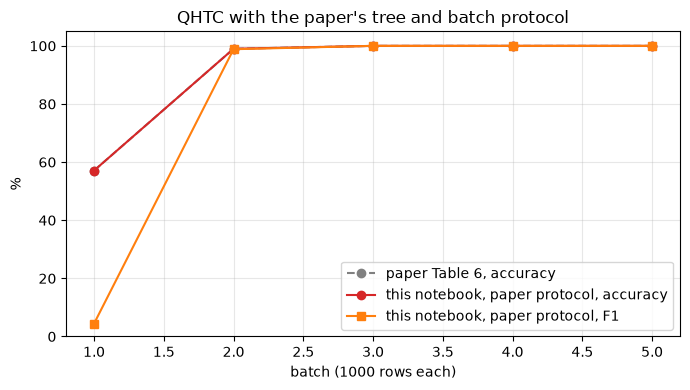

In [9]:
def hard_metrics(y_true, y_pred):
    """accuracy, F1 (DGA positive) and AUC of the hard 0/1 predictions, exactly the three columns of the paper's Table 6."""
    y_pred = np.asarray(y_pred, dtype=float).astype(int); y_true = np.asarray(y_true).astype(int)
    return dict(accuracy=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, zero_division=0),
                auc=roc_auc_score(y_true, y_pred) if len(np.unique(y_true)) > 1 else np.nan)

def run_paper_protocol(walk, labels, batch_size=BATCH_SIZE, verbose=True):
    """Algorithm 3 as published: one tree, never reset; batch k is the test set, every other row is the training set."""
    new_data = np.column_stack([walk, labels.astype(float)])
    htc = PaperHoeffdingTreeClassifier(n_features=1, n_classes=2)
    rows, preds = [], {}
    for i in range(0, len(new_data), batch_size):
        X_train = np.concatenate([new_data[:i, :-1], new_data[i + batch_size:, :-1]])
        y_train = np.concatenate([new_data[:i, -1], new_data[i + batch_size:, -1]])
        X_test, y_test = new_data[i:i + batch_size, :-1], new_data[i:i + batch_size, -1]
        t0 = time.perf_counter()
        htc.partial_fit(X_train, y_train)
        pred = np.array([p if p is not None else 0.0 for p in htc.predict(X_test)], dtype=float)
        k = i // batch_size + 1
        preds[k] = pred
        m = hard_metrics(y_test, pred) if len(X_test) > 1 else dict(accuracy=float(pred[0] == y_test[0]), f1=np.nan, auc=np.nan)
        rows.append(dict(batch=k, n_test=len(X_test), **m, seconds=time.perf_counter() - t0))
        if verbose:
            print(f"batch {k}: {len(X_test)} test rows | accuracy {100*m['accuracy']:.1f} % | F1 {100*m['f1']:.1f} % | AUC {100*m['auc']:.1f} % | {rows[-1]['seconds']:.1f} s")
    return pd.DataFrame(rows), htc, preds

t0 = time.perf_counter()
table6_ours, paper_tree, paper_preds = run_paper_protocol(walk_q, y_q)
t_qhtc_paper = time.perf_counter() - t0
full_batches = table6_ours[table6_ours.n_test == BATCH_SIZE]
avg = full_batches[["accuracy", "f1", "auc"]].mean()
print(f"\naverage over the {len(full_batches)} full batches: accuracy {100*avg.accuracy:.1f} % | F1 {100*avg.f1:.1f} % | AUC {100*avg.auc:.1f} %"
      f"   (paper's Table 6: 91.2 % | 80.7 % | 90.0 % over five batches)")
print(f"total QHTC time here: walk {t_qiskit:.0f} s (Qiskit, {n_check} rows) + tree {t_qhtc_paper:.0f} s   (paper: 1687 s on the Rigetti emulator)")

PAPER_TABLE6 = pd.DataFrame({"batch": [1, 2, 3, 4, 5], "accuracy": [57.1, 99.0, 100.0, 100.0, 100.0],
                             "f1": [4.5, 98.8, 100.0, 100.0, 100.0], "auc": [51.1, 98.9, 100.0, 100.0, 100.0]}).set_index("batch")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(PAPER_TABLE6.index, PAPER_TABLE6.accuracy, "o--", color="gray", label="paper Table 6, accuracy")
ax.plot(full_batches.batch, 100 * full_batches.accuracy, "o-", color="tab:red", label="this notebook, paper protocol, accuracy")
ax.plot(full_batches.batch, 100 * full_batches.f1, "s-", color="tab:orange", label="this notebook, paper protocol, F1")
ax.set_xlabel("batch (1000 rows each)"); ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.grid(alpha=0.3); ax.legend()
ax.set_title("QHTC with the paper's tree and batch protocol"); plt.tight_layout(); plt.show()

### Why batches 2-5 are perfect: looking inside the tree

Two properties of the published code explain the jump from 57 % to 100 %:

1. **The test rows of batch $k \ge 2$ were already training rows.** Batch 2 is tested after the tree has been fitted on
   "everything except batch 1" (which contains batch 2) *and* on "everything except batch 2". The tree is never reset,
   so by the time a batch is scored, every one of its rows has been fed to `partial_fit` at least once. Only batch 1 is
   scored before it has been seen.
2. **The tree memorises rows.** `compute_best_splitting_attribute` loops over the node's children, which are empty when a
   node is first split, so the gain is 0 for every attribute and the split always lands on attribute 0 (the only one
   here). Children are keyed by `str(value)` of the walk, a float with 16 significant digits, so almost every row gets its
   own child whose majority class is its own label. At prediction time, a value never seen falls back to the root's
   majority class (benign), a value seen before returns the label stored with it.

The cell verifies both: the root has thousands of children (one per distinct walk value), almost every row of batch 1
receives the majority class (accuracy = the benign share of the batch, F1 close to 0; the handful of DGA predictions
come from walk values that happen to coincide with a stored row), and 100 % of the rows in later batches were in an
earlier training set. The 99.0 % of batch 2 rather than 100 % comes from the few duplicated walk values whose child node
holds rows of both classes.

In [10]:
root = paper_tree.root
print(f"root: split on attribute {root.split_attr}, {len(root.children)} children for {len(np.unique(walk_q))} distinct walk values, "
      f"{root.total_samples} rows seen in total (each row is fed to partial_fit several times)")
seen = np.zeros(len(walk_q), dtype=bool)
for k in sorted(paper_preds):
    i = (k - 1) * BATCH_SIZE
    test_idx = np.arange(i, min(i + BATCH_SIZE, len(walk_q)))
    frac_seen = seen[test_idx].mean()
    train_idx = np.setdiff1d(np.arange(len(walk_q)), test_idx)   # the rows partial_fit received in this round
    seen[train_idx] = True
    pred = paper_preds[k]
    print(f"batch {k}: {100*frac_seen:5.1f} % of its rows were already training rows | predicted classes {np.unique(pred).astype(int).tolist()} "
          f"| benign share of the batch {100*(1 - y_q[test_idx].mean()):.1f} % | accuracy {100*np.mean(pred == y_q[test_idx]):.1f} %")
print("\nA tree that stores one leaf per distinct float is a lookup table, and the batch protocol asks it to look up rows it has stored.")

root: split on attribute 0, 4970 children for 4970 distinct walk values, 25005 rows seen in total (each row is fed to partial_fit several times)
batch 1:   0.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 56.1 % | accuracy 57.1 %
batch 2: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 56.1 % | accuracy 99.0 %
batch 3: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 54.8 % | accuracy 100.0 %
batch 4: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 53.8 % | accuracy 100.0 %
batch 5: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 55.5 % | accuracy 100.0 %
batch 6: 100.0 % of its rows were already training rows | predicted classes [1] | benign share of the batch 0.0 % | accuracy 100.0 %

A tree that stores one leaf per distin

## 4. The same experiment without leakage: `river`'s Hoeffding tree, fold-wise and prequential

What should Algorithm 3 have measured? Two honest protocols are run below with a textbook Hoeffding tree
(`river.tree.HoeffdingTreeClassifier`, Domingos and Hulten's VFDT with the paper's $\delta = 0.01$ and $\tau = 0.05$):

* **Fold-wise** (what Algorithm 3 intends): for each batch $k$ a *fresh* tree is trained incrementally on every other
  batch and scored on batch $k$. The standard scaler that feeds the walk is fitted on the training batches only.
* **Prequential** (how a streaming classifier is actually evaluated): a single tree sees the batches in order; each batch
  is first predicted, then learned ("test-then-train"). The first batch has no prediction yet, so the curve starts at
  batch 2.

Both are run on the quantum walk (QHTC) and on the seven standardised features themselves (the classical Hoeffding tree,
HTC, which the paper mentions but does not report). Four classical batch learners trained on identical inputs
(random forest, RBF-SVM, logistic regression, a CART decision tree) are added fold-wise, so the question "does the walk
help, and does the tree help?" has an answer.

fold-wise runs done in 30 s


Leakage-free results, mean and std over the batches (in %):


accuracy mean  accuracy std  f1 mean  f1 std  auc mean  auc std
protocol               model                 inputs                                                                                  
fold-wise, fresh model DecisionTree          7 standardised features           91.9           0.5     90.9     0.8      91.8      0.6
                                             quantum walk (1 number)           54.8           1.2     50.1     1.8      54.4      1.3
                       LogisticRegression    7 standardised features           91.5           0.6     90.3     0.8      91.2      0.7
                                             quantum walk (1 number)           58.7           0.8     41.8     1.3      56.3      0.7
                       RandomForest          7 standardised features           94.4           0.4     93.8     0.5      94.4      0.4
                                             quantum walk (1 number)           54.8           1.2     50.1     1.8      54.4      1.3
                       SVC (rbf)             7 standardised features           94.3           0.6     93.6     0.6      94.2      0.6
                                             quantum walk (1 number)           60.0           1.0     32.4     1.3      56.3      0.9
fold-wise, fresh tree  HoeffdingTree (river) 7 standardised features           86.3           0.6     85.6     0.9      86.8      0.8
                                             quantum walk (1 number)           56.1           2.2     44.6     2.3      54.6      2.0
prequential, one tree  HoeffdingTree (river) 7 standardised features           85.4           1.7     84.1     2.6      85.4      2.0
                                             quantum walk (1 number)           58.4           1.6     45.8     6.0      56.8      1.8

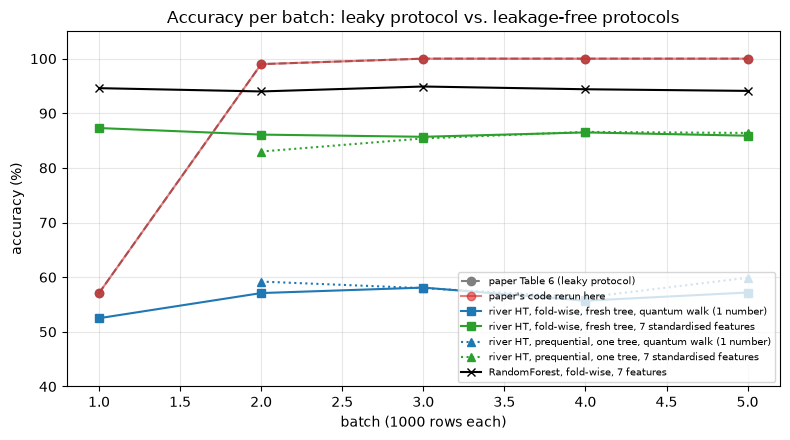

In [11]:
def make_river_ht():
    return river_tree.HoeffdingTreeClassifier(grace_period=HT_GRACE_PERIOD, delta=HT_DELTA, tau=HT_TAU)

def ht_learn(ht, X, y, names, seed):
    order = np.random.default_rng(seed).permutation(len(X))      # CHOICE: the stream order inside a batch is random
    for i in order:
        ht.learn_one(dict(zip(names, map(float, np.atleast_1d(X[i])))), int(y[i]))
    return ht

def ht_predict(ht, X, names):
    out = []
    for x in X:
        p = ht.predict_one(dict(zip(names, map(float, np.atleast_1d(x)))))
        out.append(0 if p is None else int(p))
    return np.array(out)

def classical_models():
    return {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),
            "SVC (rbf)": SVC(kernel="rbf", C=1.0, random_state=SEED),
            "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
            "DecisionTree": DecisionTreeClassifier(random_state=SEED)}

n_batches = len(walk_q) // BATCH_SIZE
batches = [np.arange(k * BATCH_SIZE, (k + 1) * BATCH_SIZE) for k in range(n_batches)]
WALK_NAME, FEAT_NAMES = ["walk"], FEATURES

fold_rows = []
t0 = time.perf_counter()
for k, test_idx in enumerate(batches, start=1):
    train_idx = np.setdiff1d(np.arange(n_batches * BATCH_SIZE), test_idx)
    scaler = StandardScaler().fit(X_q_raw[train_idx])                       # fitted on the training batches only
    Xtr7, Xte7 = scaler.transform(X_q_raw[train_idx]), scaler.transform(X_q_raw[test_idx])
    wtr, wte = quantum_walk_closed_form(Xtr7)[:, None], quantum_walk_closed_form(Xte7)[:, None]
    ytr, yte = y_q[train_idx], y_q[test_idx]
    for inputs, (Xtr, Xte, names) in {"quantum walk (1 number)": (wtr, wte, WALK_NAME), "7 standardised features": (Xtr7, Xte7, FEAT_NAMES)}.items():
        pred = ht_predict(ht_learn(make_river_ht(), Xtr, ytr, names, SEED + k), Xte, names)
        fold_rows.append(dict(protocol="fold-wise, fresh tree", model="HoeffdingTree (river)", inputs=inputs, batch=k, **hard_metrics(yte, pred)))
        for mname, model in classical_models().items():
            pred = model.fit(Xtr, ytr).predict(Xte)
            fold_rows.append(dict(protocol="fold-wise, fresh model", model=mname, inputs=inputs, batch=k, **hard_metrics(yte, pred)))
print(f"fold-wise runs done in {time.perf_counter()-t0:.0f} s")

# prequential: one tree, test-then-train over the batches in order; the scaler is fitted on batch 1 (the first data seen)
preq_rows = []
scaler = StandardScaler().fit(X_q_raw[batches[0]])
X_all7 = scaler.transform(X_q_raw[:n_batches * BATCH_SIZE]); w_all = quantum_walk_closed_form(X_all7)[:, None]
for inputs, (Xs, names) in {"quantum walk (1 number)": (w_all, WALK_NAME), "7 standardised features": (X_all7, FEAT_NAMES)}.items():
    ht = make_river_ht()
    for k, idx in enumerate(batches, start=1):
        if k > 1:
            pred = ht_predict(ht, Xs[idx], names)
            preq_rows.append(dict(protocol="prequential, one tree", model="HoeffdingTree (river)", inputs=inputs, batch=k, **hard_metrics(y_q[idx], pred)))
        ht_learn(ht, Xs[idx], y_q[idx], names, SEED + k)

leakfree = pd.DataFrame(fold_rows + preq_rows)
summary = (leakfree.groupby(["protocol", "model", "inputs"])[["accuracy", "f1", "auc"]].agg(["mean", "std"]) * 100).round(1)
summary.columns = [f"{a} {b}" for a, b in summary.columns]
print("Leakage-free results, mean and std over the batches (in %):")
display(summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(PAPER_TABLE6.index, PAPER_TABLE6.accuracy, "o--", color="gray", label="paper Table 6 (leaky protocol)")
ax.plot(full_batches.batch, 100 * full_batches.accuracy, "o-", color="tab:red", alpha=0.6, label="paper's code rerun here")
for (proto, inputs), style in {("fold-wise, fresh tree", "quantum walk (1 number)"): ("s-", "tab:blue"),
                                ("fold-wise, fresh tree", "7 standardised features"): ("s-", "tab:green"),
                                ("prequential, one tree", "quantum walk (1 number)"): ("^:", "tab:blue"),
                                ("prequential, one tree", "7 standardised features"): ("^:", "tab:green")}.items():
    d = leakfree[(leakfree.protocol == proto) & (leakfree.inputs == inputs) & (leakfree.model == "HoeffdingTree (river)")]
    ax.plot(d.batch, 100 * d.accuracy, style[0], color=style[1], label=f"river HT, {proto}, {inputs}")
d = leakfree[(leakfree.model == "RandomForest") & (leakfree.inputs == "7 standardised features")]
ax.plot(d.batch, 100 * d.accuracy, "x-", color="black", label="RandomForest, fold-wise, 7 features")
ax.set_xlabel("batch (1000 rows each)"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(40, 105); ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right"); ax.set_title("Accuracy per batch: leaky protocol vs. leakage-free protocols")
plt.tight_layout(); plt.show()

## 5. The five hybrid quantum binary classifiers on the 1000-sample file (Table 5, Aer rows)

The paper's Table 5 also lists five known classifiers on 1000 rows: VQC, PegasosQSVC, QSVC, SamplerQNN and
EstimatorQNN. Their published notebooks fix the recipe: the first 700 rows of `BotnetDgaDataset_1000.csv` are the
training set and the last 300 the test set (`train_size=700, shuffle=False`), features are scaled to $[0, \pi]$ for the
kernel methods (unscaled for the VQC), the feature map is `ZFeatureMap(7, reps=1)` and the ansatz `RealAmplitudes`.
We use one split for all models (first `TRAIN_SIZE` rows / rest), scale with a `MinMaxScaler((0, pi))` fitted on the
training rows only, and in `FAST_MODE` take only the first `N_HQBC` rows.

Before any quantum model, the classical baselines are trained on exactly these inputs; because 300 test rows make every
metric noisy (standard error about 2.5 points), the cheap models are repeated on `N_SEEDS` shuffled splits as well.

In [12]:
df_h   = df1000.iloc[:N_HQBC].reset_index(drop=True)
X_h_raw = df_h[FEATURES].values.astype(float)
y_h     = df_h["Result"].values.astype(int)

def make_split(seed=None):
    """seed None: the paper's split (first TRAIN_SIZE rows train, rest test); otherwise a stratified shuffled split."""
    if seed is None:
        tr, te = np.arange(TRAIN_SIZE), np.arange(TRAIN_SIZE, len(y_h))
    else:
        tr, te = train_test_split(np.arange(len(y_h)), train_size=TRAIN_SIZE, stratify=y_h, random_state=seed)
    scaler = MinMaxScaler((0, np.pi)).fit(X_h_raw[tr])                  # CHOICE: fitted on the training rows only (paper: on all rows)
    Xtr = scaler.transform(X_h_raw[tr]); Xte = np.clip(scaler.transform(X_h_raw[te]), 0, np.pi)
    return dict(Xtr=Xtr, Xte=Xte, ytr=y_h[tr], yte=y_h[te], Xtr_raw=X_h_raw[tr], Xte_raw=X_h_raw[te])

split0 = make_split(None)
print(f"paper split: {len(split0['ytr'])} training rows ({100*split0['ytr'].mean():.0f} % DGA), {len(split0['yte'])} test rows ({100*split0['yte'].mean():.0f} % DGA)")

def dga_metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

results = {}          # model name -> dict(metrics, y_pred, timings) on the paper split
repeat_rows = []      # cheap models on repeated splits

def record(name, inputs, y_pred, t_fit, t_pred, extra=None, quiet=False):
    r = dict(model=name, inputs=inputs, n_train=len(split0["ytr"]), n_test=len(split0["yte"]), fit_s=t_fit, predict_s=t_pred,
             y_pred=np.asarray(y_pred, dtype=int), **dga_metrics(split0["yte"], y_pred))
    r.update(extra or {})
    results[name] = r
    if not quiet:
        report([name])

def report(names):
    for name in names:
        r = results[name]
        extra = f" | {r['evaluations']} evaluations, train acc {100*r['train_accuracy']:.1f} %" if "evaluations" in r else ""
        print(f"{name:48s} accuracy {100*r['accuracy']:5.1f} % | precision {100*r['precision']:5.1f} % | recall {100*r['recall']:5.1f} % | "
              f"F1 {100*r['f1']:5.1f} % | fit {r['fit_s']:7.1f} s{extra}")

for s in range(N_SEEDS):
    d = split0 if s == 0 else make_split(SEED + s)
    for mname, model in classical_models().items():
        t0 = time.perf_counter(); model.fit(d["Xtr"], d["ytr"]); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = model.predict(d["Xte"]); t_pred = time.perf_counter() - t0
        repeat_rows.append(dict(model=mname, split=s, **dga_metrics(d["yte"], pred)))
        if s == 0:
            record(mname, "7 features in [0, pi]", pred, t_fit, t_pred)

paper split: 700 training rows (43 % DGA), 300 test rows (48 % DGA)


RandomForest                                     accuracy  89.7 % | precision  93.8 % | recall  84.1 % | F1  88.7 % | fit     0.4 s
SVC (rbf)                                        accuracy  85.0 % | precision  92.4 % | recall  75.2 % | F1  82.9 % | fit     0.0 s
LogisticRegression                               accuracy  86.3 % | precision  95.6 % | recall  75.2 % | F1  84.2 % | fit     0.0 s
DecisionTree                                     accuracy  89.3 % | precision  93.1 % | recall  84.1 % | F1  88.4 % | fit     0.0 s


### 5.1 Kernel methods: QSVC and PegasosQSVC

Both use the fidelity kernel $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$ of the 7-qubit `ZFeatureMap`
(`FidelityStatevectorKernel`, the exact statevector version of the paper's `FidelityQuantumKernel`). `QSVC` is
scikit-learn's SVC with that kernel matrix; `PegasosQSVC` is the Pegasos stochastic sub-gradient solver with the paper's
$C = 1000$ and 100 steps. Because the ZFeatureMap state is a product state, this kernel is simply
$\prod_i \cos^2(x_i - x'_i)$, which is worth knowing when reading the critical section.

In [13]:
feature_map_z = z_feature_map(N_QUBITS, reps=1)
qkernel = FidelityStatevectorKernel(feature_map=feature_map_z)

# sanity check of the product-state closed form on two training rows
a, b = split0["Xtr"][0], split0["Xtr"][1]
print(f"kernel(x0, x1): Qiskit {qkernel.evaluate(a[None], b[None])[0, 0]:.6f} | closed form prod cos^2(x_i - x'_i) = {np.prod(np.cos(a - b) ** 2):.6f}")

t0 = time.perf_counter(); qsvc = QSVC(quantum_kernel=qkernel, C=1.0); qsvc.fit(split0["Xtr"], split0["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = qsvc.predict(split0["Xte"]); t_pred = time.perf_counter() - t0
record("QSVC (ZFeatureMap kernel)", "7 features in [0, pi]", pred, t_fit, t_pred)

t0 = time.perf_counter(); peg = PegasosQSVC(quantum_kernel=qkernel, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED); peg.fit(split0["Xtr"], split0["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = peg.predict(split0["Xte"]); t_pred = time.perf_counter() - t0
record(f"PegasosQSVC (C={PEGASOS_C}, {PEGASOS_STEPS} steps)", "7 features in [0, pi]", pred, t_fit, t_pred)

# repeated splits (the paper's notebook also averages ten Pegasos runs: 0.739 there, single run 0.823)
for s in range(N_SEEDS):
    d = split0 if s == 0 else make_split(SEED + s)
    for name, model in [("QSVC (ZFeatureMap kernel)", QSVC(quantum_kernel=qkernel, C=1.0)),
                        (f"PegasosQSVC (C={PEGASOS_C}, {PEGASOS_STEPS} steps)", PegasosQSVC(quantum_kernel=qkernel, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED + s))]:
        pred = model.fit(d["Xtr"], d["ytr"]).predict(d["Xte"])
        repeat_rows.append(dict(model=name, split=s, **dga_metrics(d["yte"], pred)))
rep = pd.DataFrame(repeat_rows).groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]) * 100
print(f"\nmean +- std over {N_SEEDS} splits (paper split + {N_SEEDS-1} shuffled), in %:")
display(rep.round(1))

kernel(x0, x1): Qiskit 0.336381 | closed form prod cos^2(x_i - x'_i) = 0.336381


QSVC (ZFeatureMap kernel)                        accuracy  86.3 % | precision  93.3 % | recall  77.2 % | F1  84.5 % | fit     6.1 s


PegasosQSVC (C=1000, 100 steps)                  accuracy  77.3 % | precision  84.7 % | recall  64.8 % | F1  73.4 % | fit     1.8 s



mean +- std over 3 splits (paper split + 2 shuffled), in %:


accuracy         f1     
                                    mean  std  mean  std
model                                                   
DecisionTree                        90.4  1.9  89.4  2.2
LogisticRegression                  88.0  1.7  85.9  1.8
PegasosQSVC (C=1000, 100 steps)     80.2  2.7  77.8  4.1
QSVC (ZFeatureMap kernel)           89.9  3.1  88.5  3.5
RandomForest                        91.3  1.7  90.4  1.7
SVC (rbf)                           88.4  3.0  86.7  3.3

### 5.2 VQC: `ZFeatureMap` + `RealAmplitudes(reps=1, entanglement="pairwise")`, COBYLA, cross-entropy

The published VQC notebook composes `ZFeatureMap(7, reps=1)` with `RealAmplitudes(7, reps=1, entanglement="pairwise")`
(14 trainable angles), measures all qubits, reads the class from the parity of the bit-string and minimises the
cross-entropy with COBYLA on 1024-shot Aer runs. Two details of that notebook matter for the result: the features are
fed **unscaled** (a `CharLength` of 30 becomes a rotation of 60 rad, a reputation of 200 a rotation of 400 rad), and the
split is `random_state=7`. We train the VQC twice on our split: once on the unscaled features as the code does, once on
the $[0, \pi]$-scaled features every other model gets. The loss curve is redrawn every ten evaluations.

VQC circuit: 7 input parameters, 14 trainable parameters


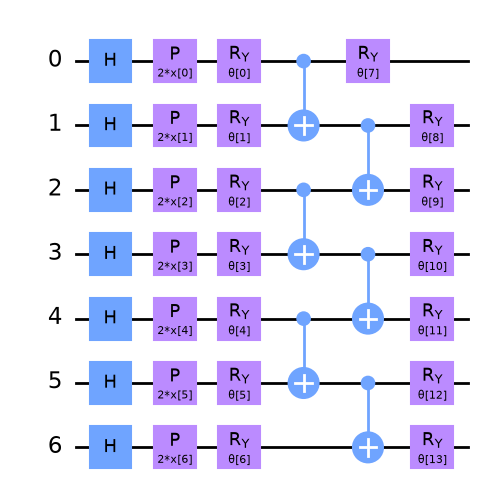

In [14]:
loss_curves = {}

def draw_losses():
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    for key, losses in loss_curves.items():
        ax.plot(losses, label=key)
    ax.set_xlabel("objective evaluation"); ax.set_ylabel("loss"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_title("Training loss (callback)"); plt.tight_layout(); plt.show()

def make_callback(key):
    loss_curves[key] = []
    def cb(weights, loss):
        loss_curves[key].append(float(loss))
        if len(loss_curves[key]) % 10 == 0:
            draw_losses()
    return cb

ansatz_vqc = real_amplitudes(N_QUBITS, reps=VQC_REPS, entanglement=VQC_ENTANGLEMENT)
print(f"VQC circuit: {feature_map_z.num_parameters} input parameters, {ansatz_vqc.num_parameters} trainable parameters")
feature_map_z.compose(ansatz_vqc).draw("mpl", fold=-1, style="clifford")

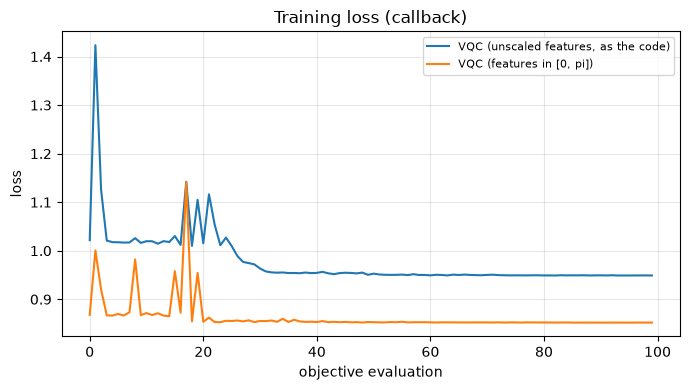

VQC (unscaled features, as the code)             accuracy  61.0 % | precision  61.3 % | recall  52.4 % | F1  56.5 % | fit   459.9 s | 100 evaluations, train acc 61.1 %
VQC (features in [0, pi])                        accuracy  61.3 % | precision  67.9 % | recall  37.9 % | F1  48.7 % | fit   396.5 s | 100 evaluations, train acc 62.6 %


In [15]:
vqc_keys = []
for key, (Xtr, Xte) in {"VQC (unscaled features, as the code)": (split0["Xtr_raw"], split0["Xte_raw"]),
                        "VQC (features in [0, pi])": (split0["Xtr"], split0["Xte"])}.items():
    algorithm_globals.random_seed = SEED
    vqc = VQC(feature_map=feature_map_z, ansatz=ansatz_vqc, loss="cross_entropy", optimizer=COBYLA(maxiter=MAXITER),
              sampler=AerSampler(default_shots=SHOTS, seed=SEED), callback=make_callback(key))
    t0 = time.perf_counter(); vqc.fit(Xtr, split0["ytr"]); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = vqc.predict(Xte); t_pred = time.perf_counter() - t0
    train_acc = float(np.mean(vqc.predict(Xtr) == split0["ytr"]))
    record(key, "unscaled" if "unscaled" in key else "7 features in [0, pi]", pred, t_fit, t_pred,
           dict(evaluations=len(loss_curves[key]), train_accuracy=train_acc), quiet=True)
    vqc_keys.append(key)
draw_losses()           # the callback clears the cell output, so the summary is printed after the final plot
report(vqc_keys)

### 5.3 SamplerQNN and EstimatorQNN

The published QNN notebooks follow the Qiskit "neural network classifier" tutorial: `ZZFeatureMap(7)` followed by
`RealAmplitudes(7, reps=1)` for the `SamplerQNN` (parity read-out, two output classes) and `ZZFeatureMap(7)` followed by
`RealAmplitudes(7)` with its default three repetitions for the `EstimatorQNN` (expectation of $Z^{\otimes 7}$, labels
$\pm 1$). The paper's text says `ZFeatureMap` for every experiment; `QNN_FEATURE_MAP` in the configuration cell lets you
choose. Both are wrapped in `NeuralNetworkClassifier` with COBYLA (the text's optimiser; the code uses SPSA) and trained
on the same training rows as every other model, which is **not** what the published notebooks do (see 5.4).

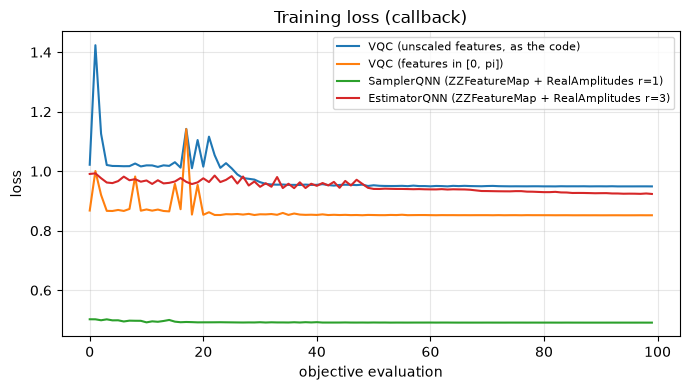

SamplerQNN (ZZFeatureMap + RealAmplitudes r=1)   accuracy  49.0 % | precision  47.1 % | recall  45.5 % | F1  46.3 % | fit   441.9 s | 100 evaluations, train acc 55.9 %
EstimatorQNN (ZZFeatureMap + RealAmplitudes r=3) accuracy  59.7 % | precision  58.6 % | recall  56.6 % | F1  57.5 % | fit    79.5 s | 100 evaluations, train acc 68.6 %


In [16]:
def qnn_feature_map():
    return zz_feature_map(N_QUBITS) if QNN_FEATURE_MAP == "zz" else z_feature_map(N_QUBITS, reps=1)

def parity(x):
    return bin(x).count("1") % 2

def build_sampler_qnn(seed):
    fm, ans = qnn_feature_map(), real_amplitudes(N_QUBITS, reps=1)
    qc = QuantumCircuit(N_QUBITS); qc.compose(fm, inplace=True); qc.compose(ans, inplace=True)
    return SamplerQNN(circuit=qc, input_params=fm.parameters, weight_params=ans.parameters, interpret=parity, output_shape=2,
                      sampler=AerSampler(default_shots=SHOTS, seed=seed))

def build_estimator_qnn(seed):
    fm, ans = qnn_feature_map(), real_amplitudes(N_QUBITS)          # reps=3 (default), as in the published notebook
    qc = QuantumCircuit(N_QUBITS); qc.compose(fm, inplace=True); qc.compose(ans, inplace=True)
    return EstimatorQNN(circuit=qc, input_params=fm.parameters, weight_params=ans.parameters,
                        estimator=AerEstimator(options={"run_options": {"shots": SHOTS, "seed_simulator": seed}}))

qnn_keys = []
algorithm_globals.random_seed = SEED
key = f"SamplerQNN ({QNN_FEATURE_MAP.upper()}FeatureMap + RealAmplitudes r=1)"
clf = NeuralNetworkClassifier(build_sampler_qnn(SEED), optimizer=COBYLA(maxiter=MAXITER), callback=make_callback(key))
t0 = time.perf_counter(); clf.fit(split0["Xtr"], split0["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = clf.predict(split0["Xte"]); t_pred = time.perf_counter() - t0
record(key, "7 features in [0, pi]", pred, t_fit, t_pred, dict(evaluations=len(loss_curves[key]), train_accuracy=float(clf.score(split0["Xtr"], split0["ytr"]))), quiet=True)
qnn_keys.append(key)

algorithm_globals.random_seed = SEED
key = f"EstimatorQNN ({QNN_FEATURE_MAP.upper()}FeatureMap + RealAmplitudes r=3)"
clf = NeuralNetworkClassifier(build_estimator_qnn(SEED), optimizer=COBYLA(maxiter=MAXITER), callback=make_callback(key))
ytr_pm, yte_pm = 2 * split0["ytr"] - 1, 2 * split0["yte"] - 1
t0 = time.perf_counter(); clf.fit(split0["Xtr"], ytr_pm); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = (clf.predict(split0["Xte"]).ravel() > 0).astype(int); t_pred = time.perf_counter() - t0
record(key, "7 features in [0, pi]", pred, t_fit, t_pred, dict(evaluations=len(loss_curves[key]), train_accuracy=float(clf.score(split0["Xtr"], ytr_pm))), quiet=True)
qnn_keys.append(key)
draw_losses()
report(qnn_keys)

### 5.4 What the paper's QNN notebooks actually scored

In both `Paper03_QNN_Sampler.ipynb` and `Paper04_QNN_Estimator.ipynb` the botnet CSV is loaded into `X, y` and the very
next cell overwrites them with the tutorial's toy problem: 50 random points in $[-1, 1]^7$ labelled by the sign of their
sum. The classifier is then fitted with SPSA on those 50 points and `score(X, y)` is evaluated **on the same 50 points**.
The printed values, 0.74 and 0.80, are the "SamplerQNN-Aer 76 %" and "EstimatorQNN-Aer 84 %" of Table 5 (the paper rounds
differently or reran once more). The cell below repeats that code path so the numbers can be compared with the botnet
results above.

In [17]:
algorithm_globals.random_seed = SEED
X_toy = 2 * algorithm_globals.random.random([50, N_QUBITS]) - 1
y_toy = 1 * (np.sum(X_toy, axis=1) >= 0)
toy = {}
for name, builder, labels in [("SamplerQNN", build_sampler_qnn, y_toy), ("EstimatorQNN", build_estimator_qnn, 2 * y_toy - 1)]:
    algorithm_globals.random_seed = SEED
    clf = NeuralNetworkClassifier(builder(SEED), optimizer=SPSA(maxiter=MAXITER))        # the published notebooks use SPSA()
    t0 = time.perf_counter(); clf.fit(X_toy, labels); t = time.perf_counter() - t0
    toy[name] = dict(train_score=float(clf.score(X_toy, labels)), seconds=t)
    print(f"{name} on the 50 synthetic points, scored on its own training set: {100*toy[name]['train_score']:.0f} % in {t:.0f} s"
          f"   (published notebook: {'74' if name == 'SamplerQNN' else '80'} %, paper Table 5: {'76' if name == 'SamplerQNN' else '84'} %)")
print("Neither number says anything about DGA detection: no botnet row was used.")

SamplerQNN on the 50 synthetic points, scored on its own training set: 82 % in 87 s   (published notebook: 74 %, paper Table 5: 76 %)


EstimatorQNN on the 50 synthetic points, scored on its own training set: 78 % in 17 s   (published notebook: 80 %, paper Table 5: 84 %)
Neither number says anything about DGA detection: no botnet row was used.


## 6. Metrics, confusion matrices and timings

DGA (class 1) is the positive class. The confusion matrices show the test rows of the paper split; the top-right cell
is a DGA name let through, the bottom-left a legitimate name blocked. Wall-clock times are on this machine's CPU with a
shot-based Aer simulator and are comparable only with each other.

Test metrics on the paper split (300 rows):


,inputs,accuracy %,precision %,recall %,F1 %,train acc %,evaluations,fit s,predict s
model,,,,,,,,,
RandomForest,"7 features in [0, pi]",89.7,93.8,84.1,88.7,NaN,NaN,0.4,0.03
SVC (rbf),"7 features in [0, pi]",85.0,92.4,75.2,82.9,NaN,NaN,0.0,0.01
LogisticRegression,"7 features in [0, pi]",86.3,95.6,75.2,84.2,NaN,NaN,0.0,0.00
DecisionTree,"7 features in [0, pi]",89.3,93.1,84.1,88.4,NaN,NaN,0.0,0.00
QSVC (ZFeatureMap kernel),"7 features in [0, pi]",86.3,93.3,77.2,84.5,NaN,NaN,6.1,3.23
"PegasosQSVC (C=1000, 100 steps)","7 features in [0, pi]",77.3,84.7,64.8,73.4,NaN,NaN,1.8,8.09
"VQC (unscaled features, as the code)",unscaled,61.0,61.3,52.4,56.5,61.1,100.0,459.9,1.98
"VQC (features in [0, pi])","7 features in [0, pi]",61.3,67.9,37.9,48.7,62.6,100.0,396.5,2.54
SamplerQNN (ZZFeatureMap + RealAmplitudes r=1),"7 features in [0, pi]",49.0,47.1,45.5,46.3,55.9,100.0,441.9,1.64


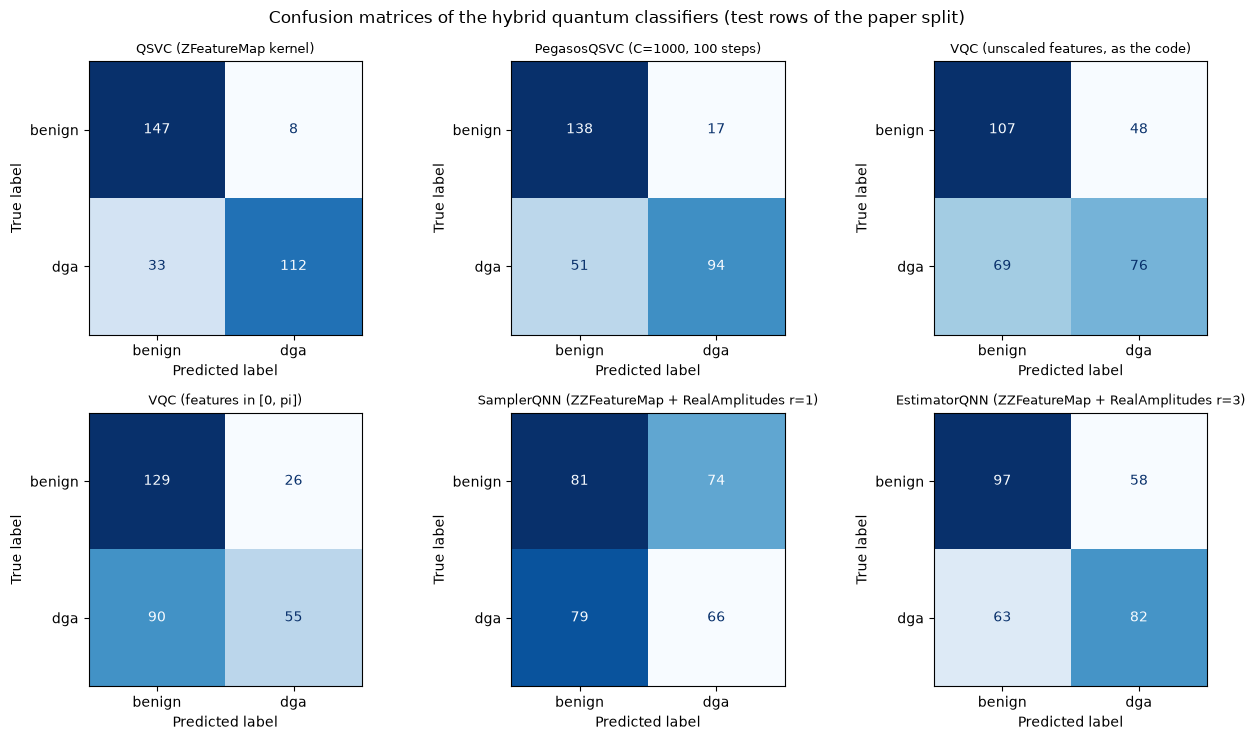

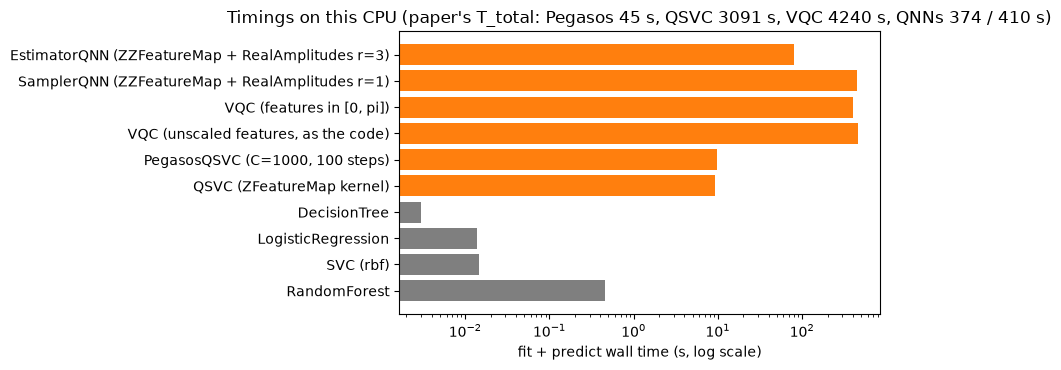

In [18]:
table5 = pd.DataFrame([{"model": r["model"], "inputs": r["inputs"], "accuracy %": round(100 * r["accuracy"], 1), "precision %": round(100 * r["precision"], 1),
                        "recall %": round(100 * r["recall"], 1), "F1 %": round(100 * r["f1"], 1), "train acc %": round(100 * r["train_accuracy"], 1) if "train_accuracy" in r else np.nan,
                        "evaluations": r.get("evaluations", np.nan), "fit s": round(r["fit_s"], 1), "predict s": round(r["predict_s"], 2)} for r in results.values()])
print(f"Test metrics on the paper split ({len(split0['yte'])} rows):")
display(table5.set_index("model"))

quantum_names = [n for n in results if any(s in n for s in ("QSVC", "Pegasos", "VQC", "QNN"))]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, name in zip(axes.ravel(), quantum_names):
    cm = confusion_matrix(split0["yte"], results[name]["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["benign", "dga"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=9)
for ax in axes.ravel()[len(quantum_names):]:
    ax.axis("off")
plt.suptitle("Confusion matrices of the hybrid quantum classifiers (test rows of the paper split)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(results); ax.barh(names, [results[n]["fit_s"] + results[n]["predict_s"] for n in names], color=["tab:orange" if n in quantum_names else "tab:gray" for n in names])
ax.set_xscale("log"); ax.set_xlabel("fit + predict wall time (s, log scale)"); ax.set_title("Timings on this CPU (paper's T_total: Pegasos 45 s, QSVC 3091 s, VQC 4240 s, QNNs 374 / 410 s)")
plt.tight_layout(); plt.show()

## 7. Paper versus this notebook

Each row is one number the paper reports. A claim is **reproduced** when our value lies within 2 accuracy points
(0.02 in F1 / AUC) of the paper's, **not reached** when it is lower by more, **exceeded** when it is higher by more, and
**cannot be checked** when the notebook cannot test it (real devices, cloud emulators, timings on other hardware). For
QHTC two rows are given per claim: the paper's own protocol (which reproduces the paper) and the leakage-free fold-wise
protocol (which is what the claim would have to mean).

In [19]:
TOL_ACC, TOL_F1 = 2.0, 2.0     # percentage points

def verdict(paper, ours, tol):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return f"exceeded (+{ours - paper:.1f})" if ours > paper else f"not reached ({ours - paper:.1f})"

def lf(proto, inputs, model="HoeffdingTree (river)"):
    d = leakfree[(leakfree.protocol == proto) & (leakfree.inputs == inputs) & (leakfree.model == model)]
    return d

rows = []
# --- Table 6: QHTC per batch and average (paper protocol, then leakage-free) ---
for k, prow in PAPER_TABLE6.iterrows():
    ours = full_batches[full_batches.batch == k]
    for metric, tol in [("accuracy", TOL_ACC), ("f1", TOL_F1), ("auc", TOL_F1)]:
        o = float(100 * ours[metric].iloc[0]) if len(ours) else np.nan
        rows.append(dict(claim=f"Table 6, batch {k}, {metric} (paper protocol)", paper=prow[metric], notebook=round(o, 1) if not np.isnan(o) else np.nan,
                         verdict=verdict(prow[metric], o, tol) if len(ours) else f"not run in FAST_MODE ({n_batches} batches)"))
avg_p = {"accuracy": 91.2, "f1": 80.7, "auc": 90.0}
for metric, tol in [("accuracy", TOL_ACC), ("f1", TOL_F1), ("auc", TOL_F1)]:
    o = float(100 * full_batches[metric].mean())
    rows.append(dict(claim=f"Table 6, average {metric} over the batches (paper protocol)", paper=avg_p[metric], notebook=round(o, 1), verdict=verdict(avg_p[metric], o, tol)))
    o2 = float(100 * lf("fold-wise, fresh tree", "quantum walk (1 number)")[metric].mean())
    rows.append(dict(claim=f"Table 6, average {metric}: leakage-free fold-wise QHTC", paper=avg_p[metric], notebook=round(o2, 1), verdict=verdict(avg_p[metric], o2, tol)))
o = float(100 * full_batches.accuracy.iloc[-1])
rows.append(dict(claim="QHTC: 100 % accuracy from the third batch on (paper protocol)", paper=100.0, notebook=round(o, 1), verdict=verdict(100.0, o, TOL_ACC)))
o2 = float(100 * lf("fold-wise, fresh tree", "quantum walk (1 number)").accuracy.max())
rows.append(dict(claim="QHTC: 100 % accuracy from the third batch on (leakage-free, best batch)", paper=100.0, notebook=round(o2, 1), verdict=verdict(100.0, o2, TOL_ACC)))
o3 = float(100 * lf("fold-wise, fresh tree", "7 standardised features").accuracy.mean())
rows.append(dict(claim="classical Hoeffding tree on the 7 features (not reported by the paper)", paper=np.nan, notebook=round(o3, 1), verdict="cannot be checked (no paper value)"))
rows.append(dict(claim="QHTC total execution time T_total (Rigetti emulator)", paper=1687.0, notebook=round(t_qiskit + t_qhtc_paper, 0),
                 verdict="cannot be checked (other hardware; our walk is simulated on " + str(n_check) + " rows)"))
# --- Table 5, Aer rows ---
P5 = {"VQC-Aer (COBYLA), 1000 samples": (54.0, "VQC (unscaled features, as the code)"),
      "VQC-Aer, same but features scaled to [0, pi] (this notebook's variant)": (54.0, "VQC (features in [0, pi])"),
      "PegasosQSVC-Aer, 1000 samples": (90.0, f"PegasosQSVC (C={PEGASOS_C}, {PEGASOS_STEPS} steps)"),
      "QSVC-Aer, 1000 samples": (87.0, "QSVC (ZFeatureMap kernel)"),
      "SamplerQNN-Aer, 1000 samples (trained on botnet rows here)": (76.0, f"SamplerQNN ({QNN_FEATURE_MAP.upper()}FeatureMap + RealAmplitudes r=1)"),
      "EstimatorQNN-Aer, 1000 samples (trained on botnet rows here)": (84.0, f"EstimatorQNN ({QNN_FEATURE_MAP.upper()}FeatureMap + RealAmplitudes r=3)")}
for claim, (p, name) in P5.items():
    o = 100 * results[name]["accuracy"]
    note = "" if N_HQBC >= 1000 else f" [FAST_MODE: {len(split0['ytr'])}/{len(split0['yte'])} rows, {MAXITER} iterations]"
    rows.append(dict(claim=claim + note, paper=p, notebook=round(o, 1), verdict=verdict(p, o, TOL_ACC)))
rows.append(dict(claim="SamplerQNN-Aer as the published code computes it (50 synthetic points, training score)", paper=76.0, notebook=round(100 * toy["SamplerQNN"]["train_score"], 1),
                 verdict=verdict(76.0, 100 * toy["SamplerQNN"]["train_score"], TOL_ACC) + " (but not on botnet data)"))
rows.append(dict(claim="EstimatorQNN-Aer as the published code computes it (50 synthetic points, training score)", paper=84.0, notebook=round(100 * toy["EstimatorQNN"]["train_score"], 1),
                 verdict=verdict(84.0, 100 * toy["EstimatorQNN"]["train_score"], TOL_ACC) + " (but not on botnet data)"))
rows.append(dict(claim="VQC-Aer by ref. [12] (Suryotrisongko & Musashi 2022), 1000 samples", paper=76.8, notebook=round(100 * results["VQC (features in [0, pi])"]["accuracy"], 1),
                 verdict="cannot be checked (another paper's run; shown for context)"))
rows.append(dict(claim="RandomForest on the same 7 features (this notebook's baseline)", paper=np.nan, notebook=round(100 * results["RandomForest"]["accuracy"], 1), verdict="cannot be checked (no paper value)"))
rows.append(dict(claim="Table 4: real devices IonQ / Rigetti / Quantinuum, 100 samples (39-59 %)", paper=59.0, notebook=np.nan, verdict="cannot be checked (needs Azure Quantum)"))
rows.append(dict(claim="Table 5: IonQ-S / Quantinuum-S / Rigetti-S emulator rows (45-63 %)", paper=63.0, notebook=np.nan, verdict="cannot be checked (needs Azure Quantum)"))
rows.append(dict(claim="Table 2 descriptive statistics (means of the 7 features)", paper=np.nan, notebook=np.nan, verdict="consistent with the 5000-row sample (section 1)"))

comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110)
display(comparison)
n_rep = int(comparison.verdict.str.startswith("reproduced").sum()); n_not = int(comparison.verdict.str.startswith("not reached").sum())
n_exc = int(comparison.verdict.str.startswith("exceeded").sum()); n_unc = int(comparison.verdict.str.startswith("cannot").sum())
print(f"\n{n_rep} reproduced, {n_not} not reached, {n_exc} exceeded, {n_unc} cannot be checked (FAST_MODE = {FAST_MODE})")

,claim,paper,notebook,verdict
0,"Table 6, batch 1, accuracy (paper protocol)",57.1,57.1,reproduced
1,"Table 6, batch 1, f1 (paper protocol)",4.5,4.5,reproduced
2,"Table 6, batch 1, auc (paper protocol)",51.1,51.1,reproduced
3,"Table 6, batch 2, accuracy (paper protocol)",99.0,99.0,reproduced
4,"Table 6, batch 2, f1 (paper protocol)",98.8,98.8,reproduced
5,"Table 6, batch 2, auc (paper protocol)",98.9,98.9,reproduced
6,"Table 6, batch 3, accuracy (paper protocol)",100.0,100.0,reproduced
7,"Table 6, batch 3, f1 (paper protocol)",100.0,100.0,reproduced
8,"Table 6, batch 3, auc (paper protocol)",100.0,100.0,reproduced
9,"Table 6, batch 4, accuracy (paper protocol)",100.0,100.0,reproduced



20 reproduced, 8 not reached, 3 exceeded, 6 cannot be checked (FAST_MODE = False)


## Reading the paper critically

**The 100 % is a memorisation artefact, and so is the 91.2 % average.** Section 3 reproduces Table 6 to the decimal
with the authors' own code, and section 3's diagnostic cell shows how: the tree is never reset between batches, so every
row of batches 2-5 has already been passed to `partial_fit` before it is scored; the tree splits on the only attribute
and creates one child per distinct floating-point walk value, so scoring a stored row returns the label stored with it.
Batch 1, the only batch scored before it was seen, gets the majority class for every row: 57.1 % accuracy is the benign
share of that batch and an F1 of 4.5 % means almost no DGA name was caught. The leakage-free runs of section 4 give the
honest value of the method: a Hoeffding tree on the walk reaches about 56-58 % accuracy (fold-wise or prequential), a
few points above the 55 % benign share and no better than a logistic regression on the same number, while the same
tree on the seven features reaches about 86 % and a random forest about 94 %.

**The "quantum walk" is a classical formula that throws most of the information away.** `ZFeatureMap` with no
entangling gates prepares a product state; the trace distance between two product-state qubits is
$|\sin(x_i - x_{i+1})|$, so the quantum computer evaluates $\sum_i |\sin(x_i - x_{i+1})|$, a number any CPU computes
in nanoseconds (section 2 checks this against the Qiskit simulation to $10^{-9}$). The map is many-to-one: shifting
all seven features by the same amount leaves it unchanged, and the paper itself notes that it depends on the arbitrary
column order. Reducing seven informative features to one such scalar before the classifier cannot add information; it
can only lose it, which is what the fold-wise comparison "walk vs. seven features" measures.

**The Hoeffding tree in the code is not a Hoeffding tree.** Domingos and Hulten's algorithm chooses the split
attribute whose information gain beats the runner-up by the Hoeffding bound, with numeric attributes split at a
threshold. The published class computes the gain over the children of an unsplit node (none), always picks attribute 0,
and uses the raw float as a categorical key. The "incremental" and "speed-up" claims therefore rest on a lookup table.
`river` (used here) or `scikit-multiflow` (which the paper cites as its reference implementation) provide the real
algorithm; the paper does not report running it.

**The QNN numbers of Table 5 were not measured on botnet data.** Both QNN notebooks overwrite the loaded CSV with 50
random synthetic points, train with SPSA (not COBYLA) on a `ZZFeatureMap` (not `ZFeatureMap`) and score on the training
set (section 5.4). Trained on the botnet rows with the paper's stated settings, the two QNNs land where the other
variational models do.

**The VQC is fed unscaled angles, QSVC/Pegasos are scaled on all rows, and Pegasos' 90 % is a single run.** The
published VQC notebook passes a 30-character length as a 60-radian rotation; the kernel notebooks fit their scaler on
training and test rows together; the Pegasos notebook prints 82.3 % for one run and 73.9 % as the mean of ten, yet
Table 5 says 90 % (here: 77 % on the paper's split, 80 +- 3 % over three splits). The QSVC's 87 % does reproduce (86 %
here), but a logistic regression on the same seven numbers does as well and a random forest better, so the kernel adds
nothing either. With 300 test rows the standard error is about 2.5 points, so single-run differences of five points
between the HQBCs are noise; our repeated splits show that.

**"Two orders of magnitude faster" compares different jobs.** The 1687 s of QHTC on the Rigetti emulator buys 5000
single-qubit-product circuits with no optimiser loop; the other rows buy hundreds of optimiser iterations over 700
circuits each, on cloud emulators with queueing. The kernel SVM (QSVC) with an exact statevector kernel runs in seconds
here. Speed claims only mean something at equal accuracy on an equal protocol, and section 4 shows that the walk-based
tree is not competitive on accuracy.

**What stands.** The engineering contribution, hardening long Azure Quantum jobs so that 100-sample runs complete on
three real devices (Table 4), is real but unverifiable here, and those runs score 39-59 %, i.e. at chance. The features
of the IEEE Botnet DGA dataset are strong (a random forest on seven numbers exceeds 90 % on 1000 rows); the paper's own
closing remark that `EntropyValue` and `RelativeEntropy` "possess strong predictor properties" is the right lead.

## Exercises

1. **Order dependence.** The walk depends on the column order. Permute the seven features (`FEATURES`), recompute the
   walk and rerun section 4's fold-wise tree. How much does the accuracy move? Then try the ordering that maximises the
   AUC of the walk on the training batches only. Is the optimised order still a "quantum" quantity?
2. **Entangle the feature map.** Replace `z_feature_map` by `zz_feature_map(7, reps=1)` in `quantum_walk_qiskit`. The
   reduced states are now mixed, so the closed form no longer applies and the trace distance has to be computed from the
   density matrices. Does the walk become more informative (AUC in section 2) or less? What does it cost in time?
3. **A real Hoeffding tree on a real stream.** Run `river`'s tree prequentially on the full 5001 rows one at a time
   (`learn_one` after each `predict_one`) and plot the running accuracy with `river.metrics.Accuracy`. Compare the
   seven-feature tree with the walk tree and with a `river.linear_model.LogisticRegression`. At how many rows does the
   seven-feature tree reach 90 %?
4. **Fix the split and the scaling in the HQBC experiments.** Change `make_split` to the paper's `random_state=7`
   split and fit the `MinMaxScaler` on all 1000 rows as the published code does. Do the QSVC and Pegasos numbers move by
   more than the split-to-split standard deviation reported in section 5.1? Then raise `MAXITER` for the VQC and look at
   the loss curve: does COBYLA converge, and does the scaled VQC beat the unscaled one?
5. **Leakage detector.** Write a function that, given any batch protocol (a list of (train_idx, test_idx) pairs run on a
   single persistent model), reports for every batch the fraction of test rows that were in an earlier training set.
   Apply it to Algorithm 3 and to the fold-wise and prequential protocols of section 4. Explain why a persistent model
   plus overlapping test sets is a problem for *any* learner, not only for a lookup table.